# 02. Baselines and modelling

Every number in this notebook comes from the MLflow runs that `python src/train.py` logs. The notebook reads them back
instead of re-training, so the report, the notebook and the tracker always agree. Run `python src/train.py` once before
opening this notebook on a fresh clone.

Metrics:

* **PR-AUC** (average precision). The main ranking metric. A random ranking scores the base rate, 0.156.
* **Precision at 10%**: of the 10% of sessions that would get the pop-up, the share that really bought. Random is about 0.16.
* **ROC-AUC** as a secondary number.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from src import config, data, evaluate, features
import mlflow

mlflow.set_tracking_uri(config.MLFLOW_URI)
runs = mlflow.search_runs(experiment_names=[config.EXPERIMENT_NAME])
print(len(runs), "runs in experiment", config.EXPERIMENT_NAME)
runs[["tags.mlflow.runName", "tags.kind", "tags.feature_set"]].rename(columns=lambda c: c.split(".")[-1])

15 runs in experiment online-shoppers-popup


,runName,kind,feature_set
0,drift_check_psi,monitoring,NaN
1,month_check_train_feb_oct_test_nov_dec,robustness_check,no_pagevalues
2,COMPARISON_random_forest_with_pagevalues_do_no...,comparison,with_pagevalues
3,FINAL_hist_gradient_boosting_no_pagevalues,final,no_pagevalues
4,leakage_check_pagevalues,leakage_check,NaN
5,tuned_random_forest_with_pagevalues,candidate_model,with_pagevalues
6,tuned_hist_gradient_boosting_with_pagevalues,candidate_model,with_pagevalues
7,tuned_logistic_regression_with_pagevalues,candidate_model,with_pagevalues
8,tuned_random_forest_no_pagevalues,candidate_model,no_pagevalues
9,tuned_hist_gradient_boosting_no_pagevalues,candidate_model,no_pagevalues


## 1. Baselines

Four baselines, all scored on the same CV folds and the same test rows:

1. **Constant, "nobody buys".** It cannot rank anyone, so picking 10% of sessions with it is a random pick.
2. **Rule A: page value above zero.** The obvious one-liner. It uses the suspect column.
3. **Rule B: 20 or more product pages and an exit rate below 0.025.** The obvious rule without page value. The
   thresholds were written in the charter before any modelling.
4. **Logistic regression on four columns**: product pages, time on product pages, bounce rate, exit rate.

In [2]:
def run_table(kind_filter):
    cols = {
        "tags.mlflow.runName": "run", "tags.feature_set": "feature set",
        "metrics.cv_pr_auc_mean": "CV PR-AUC", "metrics.cv_pr_auc_std": "CV std",
        "metrics.test_pr_auc": "test PR-AUC", "metrics.test_roc_auc": "test ROC-AUC",
        "metrics.test_precision_at_10pct": "test precision@10%", "metrics.test_recall_at_10pct": "test recall@10%",
        "metrics.test_accuracy_at_0_5": "test accuracy",
    }
    part = runs[runs["tags.kind"].isin(kind_filter)]
    return part[[c for c in cols if c in part]].rename(columns=cols).sort_values("CV PR-AUC").round(3).reset_index(drop=True)

run_table(["baseline"])

,run,feature set,CV PR-AUC,CV std,test PR-AUC,test ROC-AUC,test precision@10%,test recall@10%,test accuracy
0,baseline_constant_nobody_buys,none,0.156,0.000,0.156,0.500,0.164,0.105,0.844
1,baseline_rule_B_products_and_low_exit,no_pagevalues,0.217,0.011,0.217,0.633,0.242,0.154,0.700
2,baseline_logreg_4_features,simple_4,0.298,0.024,0.301,0.728,0.348,0.223,0.844
3,baseline_rule_A_pagevalue_above_0,with_pagevalues,0.483,0.015,0.493,0.849,0.545,0.348,0.875


**What the baselines say.**

* "Nobody buys" is 84% accurate and completely useless. Accuracy would rank it above Rule B. That is why accuracy is
  never the headline here.
* Rule A, one line using page value, reaches PR-AUC near 0.5 and 55% precision at 10%. If page value were usable, a
  rule would already be a strong answer, and the "is this an ML problem?" question would lean towards "no".
* Without page value, the best rule (B) only gets 0.22 PR-AUC and 24% precision. The four-column logistic regression
  already does better (0.30). So without page value, a model is needed.

## 2. Two (three) model families, tuned inside cross-validation

Each family is tuned with `GridSearchCV` on the training rows only, using stratified 5-fold CV and PR-AUC as the score.
The whole pipeline (engineered features, log transform, scaling, one-hot encoding) sits inside each fold, so nothing is
fitted on validation rows. Each family is tuned twice: **without** `PageValues` (deployable) and **with** it (comparison).

In [3]:
tuned = run_table(["candidate_model"])[["run", "feature set", "CV PR-AUC", "CV std"]]
params = runs[runs["tags.kind"] == "candidate_model"].set_index("tags.mlflow.runName")
param_cols = [c for c in params.columns if c.startswith("params.") and c.split(".")[1] in
              ("C", "learning_rate", "max_depth", "max_iter", "l2_regularization", "min_samples_leaf", "max_features")]
best = params[param_cols].rename(columns=lambda c: c.split(".")[1])
best = best.apply(lambda r: ", ".join(f"{k}={v}" for k, v in r.items() if pd.notna(v)), axis=1)
tuned["best settings"] = tuned["run"].map(best)
tuned

,run,feature set,CV PR-AUC,CV std,best settings
0,tuned_logistic_regression_no_pagevalues,no_pagevalues,0.342,0.028,C=0.03
1,tuned_random_forest_no_pagevalues,no_pagevalues,0.383,0.027,"min_samples_leaf=5, max_features=sqrt, max_dep..."
2,tuned_hist_gradient_boosting_no_pagevalues,no_pagevalues,0.384,0.019,"max_depth=6, learning_rate=0.03, l2_regulariza..."
3,tuned_logistic_regression_with_pagevalues,with_pagevalues,0.684,0.019,C=0.03
4,tuned_hist_gradient_boosting_with_pagevalues,with_pagevalues,0.753,0.022,"max_depth=6, learning_rate=0.03, l2_regulariza..."
5,tuned_random_forest_with_pagevalues,with_pagevalues,0.754,0.021,"min_samples_leaf=20, max_features=0.3, max_dep..."


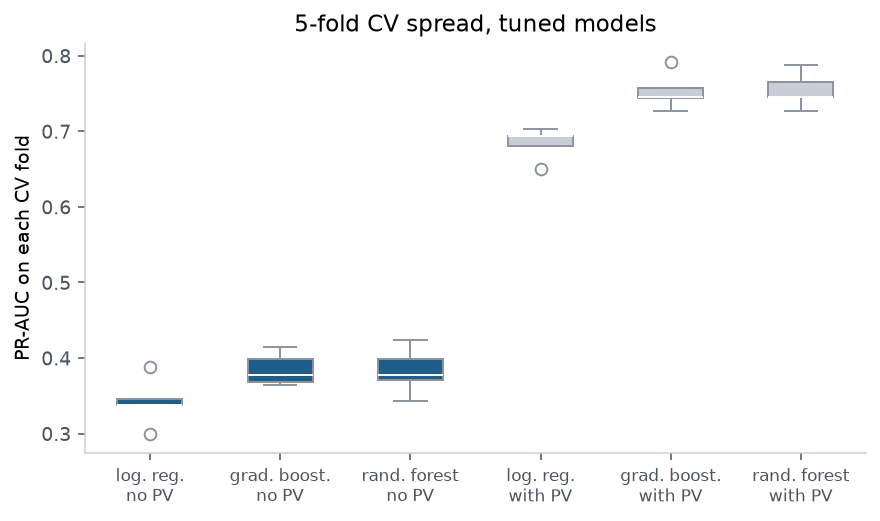

In [4]:
from IPython.display import Image
Image(filename=str(config.FIGURES_DIR / "cv_fold_spread.png"))

**Reading the fold spread.**

* Without page value, gradient boosting and random forest tie at about 0.38 CV PR-AUC, and both beat the tuned
  logistic regression (0.34). The fold-to-fold spread (about ±0.02 to ±0.03) is as big as the gap between the two tree
  models, so the choice between them is close to a coin flip. Gradient boosting is picked because its CV mean is a
  hair higher and its spread is smaller.
* With page value, every family jumps to 0.68 to 0.75. The gap between the two feature sets (about 0.37 PR-AUC) is ten
  times bigger than any gap between families. One column matters more than the choice of algorithm, which is the same
  warning sign from notebook 01, now measured.

## 3. The PageValues decision

The `leakage_check_pagevalues` run stores the evidence in one place.

In [5]:
leak = runs[runs["tags.mlflow.runName"] == "leakage_check_pagevalues"].iloc[0]
evidence = {k.replace("metrics.", ""): round(v, 3) for k, v in leak.items() if k.startswith("metrics.") and pd.notna(v)}
pd.Series(evidence).to_frame("value")

,value
best_cv_pr_auc_without_pagevalues,0.384
cv_pr_auc_gain_from_pagevalues,0.369
share_of_nonbuyers_with_pagevalue,0.116
buy_rate_pagevalue_0,0.039
share_of_buyers_with_pagevalue,0.805
best_cv_pr_auc_with_pagevalues,0.754
pagevalues_alone_pr_auc,0.620
pagevalues_alone_roc_auc,0.862
buy_rate_pagevalue_above_0,0.561


**Decision: the deployed model does not use `PageValues`.**

1. *Definition.* GA credits a page with the revenue of transactions that come after it in the same session. A buying
   session's own purchase feeds its own page values, so the feature partly contains the label.
2. *Point in time.* At the exit-intent moment, the purchase has not happened. The value in this file was computed after
   the fact, and it cannot be rebuilt from a frozen, earlier lookup because the file has no page IDs or dates.
3. *Evidence.* 80% of buyers have a page value against 12% of non-buyers, the column alone beats every model built on
   all the other columns, and adding it lifts CV PR-AUC from 0.38 to 0.75.

The with-PageValues model is still trained, tested and logged (`COMPARISON_..._do_not_deploy`), because it is a fair
upper bound on what a real-time page-value lookup could add. Building that lookup is the main next step.

## 4. Final model on the test set (touched once)

The family was chosen by CV PR-AUC on the training rows. Only then were the test rows scored. The threshold is the 90th
percentile of the out-of-fold training scores, so on new data it should flag about 10% of sessions.

In [6]:
run_table(["final", "comparison", "baseline"])

,run,feature set,CV PR-AUC,CV std,test PR-AUC,test ROC-AUC,test precision@10%,test recall@10%,test accuracy
0,baseline_constant_nobody_buys,none,0.156,0.000,0.156,0.500,0.164,0.105,0.844
1,baseline_rule_B_products_and_low_exit,no_pagevalues,0.217,0.011,0.217,0.633,0.242,0.154,0.700
2,baseline_logreg_4_features,simple_4,0.298,0.024,0.301,0.728,0.348,0.223,0.844
3,FINAL_hist_gradient_boosting_no_pagevalues,no_pagevalues,0.384,0.019,0.372,0.790,0.451,0.288,0.841
4,baseline_rule_A_pagevalue_above_0,with_pagevalues,0.483,0.015,0.493,0.849,0.545,0.348,0.875
5,COMPARISON_random_forest_with_pagevalues_do_no...,with_pagevalues,0.754,0.021,0.753,0.931,0.803,0.513,0.905


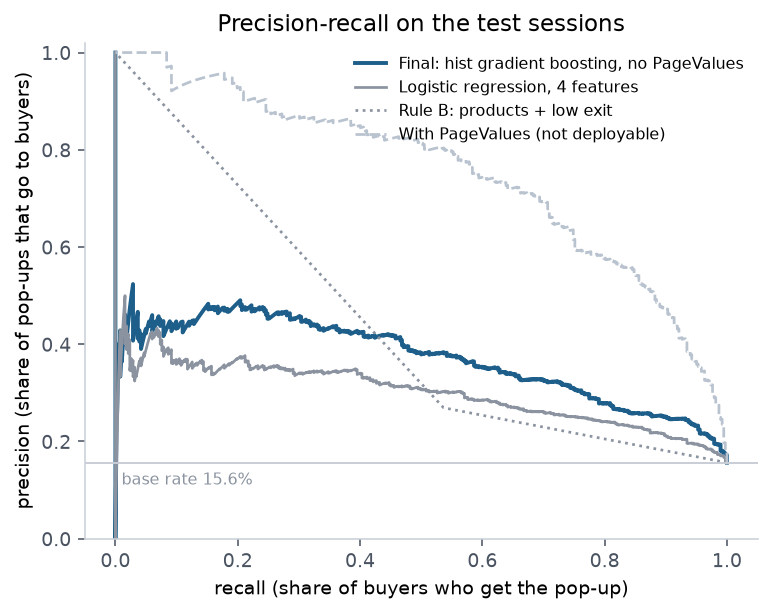

In [7]:
Image(filename=str(config.FIGURES_DIR / "pr_curve_test.png"))

**Against the charter (written before modelling).**

| Criterion | Target | Result |
|---|---|---|
| Test PR-AUC | at least 0.30 | 0.372, met |
| Precision at 10% | at least 0.35 | 0.451, met |
| Beat best no-page-value rule (B) by PR-AUC | by at least 0.05 | +0.155, met |
| Beat Rule B on precision at 10% too (kill criterion a) | must | 0.451 against 0.242, met |

The CV estimate (0.384 ± 0.019) and the test score (0.372) agree, so the test result is not a lucky draw. The model
does not come close to Rule A. That comparison is not fair, though, because Rule A uses the column we just decided
cannot be used.

In [8]:
final_id = (config.REPORTS_DIR / "final_run_id.txt").read_text().strip()
client = mlflow.tracking.MlflowClient()
version = client.get_model_version_by_alias(config.REGISTERED_MODEL_NAME, "champion")
print("final run id:", final_id)
print("registered:", config.REGISTERED_MODEL_NAME, "version", version.version, "alias champion, from run", version.run_id)
reloaded = mlflow.sklearn.load_model(f"models:/{config.REGISTERED_MODEL_NAME}@champion")
print(type(reloaded.named_steps["model"]).__name__)

final run id: a3bb379198604ce29b251049a71c2de3
registered: shoppers-popup-purchase version 1 alias champion, from run a3bb379198604ce29b251049a71c2de3


HistGradientBoostingClassifier


The final model can be reloaded from the registry by alias, or from `models/model.joblib`. Notebook 03 checks that
the two give the same predictions and then looks at where the model goes wrong.